# 01 — MEMS Dynamical System

## Objective

This notebook develops and validates the deterministic physical model used in the MEMS Scientific Machine Learning study.

The initial system is represented as a forced mass-spring-damper model:

$$
m\ddot{x}(t)
+
c\dot{x}(t)
+
kx(t)
+
\alpha x^3(t)
=
F(t)
$$

where:

- $m$ is the effective mass,
- $c$ is the damping coefficient,
- $k$ is the linear stiffness,
- $\alpha$ is the nonlinear stiffness coefficient,
- $F(t)$ is the applied excitation,
- $x(t)$ is the displacement response.

The purpose of this notebook is to validate the deterministic simulation before introducing Monte Carlo uncertainty, equation discovery, machine learning, or causal analysis.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from src.dynamics import (
    MEMSParameters,
    natural_angular_frequency,
    natural_frequency,
    damping_ratio,
)


from src.excitation import chirp_excitation


from src.sensors import SensorParameters


from src.simulation import simulate_mems_system


from src.utils import (
    load_yaml_config,
    config_path,
    data_path,
    figures_path,
    ensure_directory,
)

In [2]:
# LOAD THE BASE CONFIGURATION

# Load the YAML configuration file that contains the
# deterministic simulation settings for the MEMS model.
config = load_yaml_config(
    config_path("base_config.yaml")
)

# Display the complete configuration dictionary so that
# we can verify that the YAML file has been read correctly.
config

{'project': {'name': 'monte_carlo_mems_sciml', 'seed': 9512},
 'simulation': {'start_time': 0.0,
  'end_time': 2.0,
  'sampling_frequency': 10000,
  'solver': {'method': 'RK45', 'rtol': 1e-08, 'atol': 1e-10}},
 'initial_conditions': {'displacement': 0.0, 'velocity': 0.0},
 'physical_model': {'model_type': 'nonlinear_mass_spring_damper',
  'mass': 1.0,
  'damping': 0.08,
  'stiffness': 1000.0,
  'nonlinear_stiffness': 0.0},
 'excitation': {'type': 'chirp',
  'amplitude': 1.0,
  'start_frequency': 1.0,
  'end_frequency': 20.0},
 'sensor': {'output': 'acceleration',
  'gain': 1.0,
  'bias': 0.0,
  'noise': {'enabled': False, 'standard_deviation': 0.0}},
 'environment': {'reference_temperature': 25.0,
  'temperature': 25.0,
  'ageing': 0.0,
  'mechanical_stress': 0.0}}

In [3]:
# EXTRACT THE MAIN CONFIGURATION BLOCKS

# Separate the major sections of the configuration dictionary.
# This makes the following code easier to read and avoids
# repeatedly writing config["..."] throughout the notebook.

physical_config = config["physical_model"]
simulation_config = config["simulation"]
excitation_config = config["excitation"]
sensor_config = config["sensor"]
initial_conditions = config["initial_conditions"]
environment_config = config["environment"]


# Print each configuration block so that we can verify
# that the expected parameters have been extracted correctly.

print("Physical model configuration:")
print(physical_config)

print("\nSimulation configuration:")
print(simulation_config)

print("\nExcitation configuration:")
print(excitation_config)

print("\nSensor configuration:")
print(sensor_config)

print("\nInitial conditions:")
print(initial_conditions)

print("\nEnvironment configuration:")
print(environment_config)

Physical model configuration:
{'model_type': 'nonlinear_mass_spring_damper', 'mass': 1.0, 'damping': 0.08, 'stiffness': 1000.0, 'nonlinear_stiffness': 0.0}

Simulation configuration:
{'start_time': 0.0, 'end_time': 2.0, 'sampling_frequency': 10000, 'solver': {'method': 'RK45', 'rtol': 1e-08, 'atol': 1e-10}}

Excitation configuration:
{'type': 'chirp', 'amplitude': 1.0, 'start_frequency': 1.0, 'end_frequency': 20.0}

Sensor configuration:
{'output': 'acceleration', 'gain': 1.0, 'bias': 0.0, 'noise': {'enabled': False, 'standard_deviation': 0.0}}

Initial conditions:
{'displacement': 0.0, 'velocity': 0.0}

Environment configuration:
{'reference_temperature': 25.0, 'temperature': 25.0, 'ageing': 0.0, 'mechanical_stress': 0.0}


In [4]:
# CREATE THE PHYSICAL MEMS PARAMETER OBJECT

# Create a structured MEMSParameters object using the values
# loaded from base_config.yaml.
#
# This object will be passed directly to the dynamical-system
# functions and numerical simulator.

parameters = MEMSParameters(
    mass=physical_config["mass"],
    damping=physical_config["damping"],
    stiffness=physical_config["stiffness"],
    nonlinear_stiffness=physical_config["nonlinear_stiffness"],
)


# Validate the parameters using the checks defined in dynamics.py.
# The validation ensures, for example, that mass and stiffness
# are positive and that damping is non-negative.

parameters.validate()


# Display the resulting parameter object.
parameters

MEMSParameters(mass=1.0, damping=0.08, stiffness=1000.0, nonlinear_stiffness=0.0)

In [5]:
# CALCULATE BASIC PHYSICAL PROPERTIES

# Calculate the undamped natural angular frequency:
#
#     omega_n = sqrt(k / m)
#
# Units: rad/s
omega_n = natural_angular_frequency(parameters)


# Convert the natural angular frequency to ordinary frequency:
#
#     f_n = omega_n / (2*pi)
#
# Units: Hz
f_n = natural_frequency(parameters)


# Calculate the dimensionless damping ratio:
#
#     zeta = c / (2*sqrt(k*m))
#
# This indicates whether the system is underdamped,
# critically damped, or overdamped.
zeta = damping_ratio(parameters)


# Display the calculated physical quantities.
print(f"Natural angular frequency: {omega_n:.6f} rad/s")
print(f"Natural frequency:         {f_n:.6f} Hz")
print(f"Damping ratio:             {zeta:.8f}")

Natural angular frequency: 31.622777 rad/s
Natural frequency:         5.032921 Hz
Damping ratio:             0.00126491


## Physical Baseline

For the initial deterministic parameter set, the calculated natural angular frequency is

$$
\omega_n = 31.622777\ \text{rad/s},
$$

corresponding to a natural frequency of

$$
f_n = 5.032921\ \text{Hz}.
$$

The damping ratio is

$$
\zeta = 0.00126491.
$$

Since $0 < \zeta \ll 1$, the current baseline represents a strongly underdamped dynamical system. Consequently, a pronounced dynamic response can be expected when the excitation frequency approaches the natural frequency.

The planned chirp excitation spans from $1$ Hz to $20$ Hz and therefore crosses the natural-frequency region around $5.03$ Hz. This is useful for the initial system-identification study because the excitation covers a dynamically informative frequency range.

The current numerical values are development parameters used to validate the computational workflow. They are not yet treated as experimentally validated parameters of a specific industrial MEMS gyroscope.

In [6]:
# DEFINE THE CHIRP EXCITATION

# Calculate the total simulation duration from the configuration.
simulation_duration = (
    simulation_config["end_time"]
    - simulation_config["start_time"]
)


# Create the excitation function using the chirp settings
# stored in base_config.yaml.
#
# The chirp frequency increases linearly from the configured
# start frequency to the configured end frequency over the
# complete simulation duration.

excitation = chirp_excitation(
    amplitude=excitation_config["amplitude"],
    start_frequency=excitation_config["start_frequency"],
    end_frequency=excitation_config["end_frequency"],
    duration=simulation_duration,
)


# Display the main excitation settings for verification.
print(f"Excitation type:       {excitation_config['type']}")
print(f"Amplitude:              {excitation_config['amplitude']}")
print(
    f"Start frequency:        "
    f"{excitation_config['start_frequency']:.2f} Hz"
)
print(
    f"End frequency:          "
    f"{excitation_config['end_frequency']:.2f} Hz"
)
print(f"Simulation duration:    {simulation_duration:.2f} s")

Excitation type:       chirp
Amplitude:              1.0
Start frequency:        1.00 Hz
End frequency:          20.00 Hz
Simulation duration:    2.00 s


In [7]:
# ESTIMATE THE RESONANCE-CROSSING TIME

# Read the starting and ending chirp frequencies.
start_frequency = excitation_config["start_frequency"]
end_frequency = excitation_config["end_frequency"]


# Calculate how quickly the excitation frequency increases.
#
# Example:
# (20 Hz - 1 Hz) / 2 s = 9.5 Hz/s
sweep_rate = (
    end_frequency - start_frequency
) / simulation_duration


# Calculate the time at which the chirp frequency becomes equal
# to the natural frequency of the MEMS system.
#
# Starting from:
#
#     f_n = f_start + sweep_rate * t
#
# we rearrange to:
#
#     t = (f_n - f_start) / sweep_rate
resonance_crossing_time = (
    f_n - start_frequency
) / sweep_rate


# Print the important values.
print(f"Chirp sweep rate:         {sweep_rate:.6f} Hz/s")
print(f"Natural frequency:        {f_n:.6f} Hz")
print(f"Predicted resonance time: {resonance_crossing_time:.6f} s")

Chirp sweep rate:         9.500000 Hz/s
Natural frequency:        5.032921 Hz
Predicted resonance time: 0.424518 s


## Excitation and Resonance Prediction

The deterministic system is excited using a linear chirp signal whose frequency increases from $1$ Hz to $20$ Hz over a duration of $2$ s.

The corresponding frequency sweep rate is

$$
r = 9.5\ \text{Hz/s}.
$$

The natural frequency of the baseline system is

$$
f_n = 5.032921\ \text{Hz}.
$$

For a linear chirp,

$$
f(t) = f_{\mathrm{start}} + rt.
$$

The excitation therefore reaches the natural-frequency region at

$$
t_{\mathrm{res}} = 0.424518\ \text{s}.
$$

This gives a useful prediction before the dynamic simulation is performed. Since the system is strongly underdamped, an increased response is expected when the excitation passes through this frequency region.

The maximum response does not necessarily have to occur exactly at $0.424518$ s because the system requires time to respond to the changing excitation. The subsequent simulation will therefore be used to examine whether the expected resonance behaviour appears in the displacement, velocity, and acceleration responses.

In [8]:
# CREATE THE SENSOR PARAMETER OBJECT

# The physical simulation gives us the "true" response of the system.
#
# A real sensor, however, can modify that response through:
#
# 1. gain  -> multiplication of the true signal
# 2. bias  -> constant offset
# 3. noise -> random measurement error
#
# The measurement model is:
#
#     y_measured = gain * y_true + bias + noise
#
# For the first deterministic experiment, we intentionally use
# an ideal sensor so that we can validate the physical model first.

sensor_parameters = SensorParameters(
    gain=sensor_config["gain"],
    bias=sensor_config["bias"],
    noise_standard_deviation=(
        sensor_config["noise"]["standard_deviation"]
    ),
)


# Check that the values are valid.
sensor_parameters.validate()


# Display the sensor parameter object.
sensor_parameters

SensorParameters(gain=1.0, bias=0.0, noise_standard_deviation=0.0)

In [9]:
# RUN THE DETERMINISTIC MEMS SIMULATION

# We now solve the MEMS differential equation over time.
#
# The simulation combines:
#
# 1. the physical MEMS parameters,
# 2. the chirp excitation,
# 3. the initial displacement and velocity,
# 4. the numerical solver settings,
# 5. the ideal sensor model.
#
# The solver calculates how the displacement, velocity,
# and acceleration of the system evolve during the 2-second
# excitation experiment.

simulation_result = simulate_mems_system(
    parameters=parameters,
    excitation_function=excitation,

    start_time=simulation_config["start_time"],
    end_time=simulation_config["end_time"],
    sampling_frequency=simulation_config["sampling_frequency"],

    initial_displacement=initial_conditions["displacement"],
    initial_velocity=initial_conditions["velocity"],

    sensor_parameters=sensor_parameters,
    sensor_output=sensor_config["output"],

    solver_method=simulation_config["solver"]["method"],
    rtol=simulation_config["solver"]["rtol"],
    atol=simulation_config["solver"]["atol"],

    random_seed=config["project"]["seed"],
)

simulation_result

SimulationResult(time=array([0.0000e+00, 1.0000e-04, 2.0000e-04, ..., 1.9998e+00, 1.9999e+00,
       2.0000e+00], shape=(20001,)), displacement=array([0.00000000e+00, 1.04744362e-12, 8.38110181e-12, ...,
       2.41115562e-03, 2.42284774e-03, 2.43451541e-03], shape=(20001,)), velocity=array([0.00000000e+00, 3.14257639e-08, 1.25742185e-07, ...,
       1.17043459e-01, 1.16798938e-01, 1.16554508e-01], shape=(20001,)), acceleration=array([ 0.00000000e+00,  6.28613379e-04,  1.25781209e-03, ...,
       -2.44564800e+00, -2.44475739e+00, -2.44383977e+00], shape=(20001,)), excitation=array([ 0.00000000e+00,  6.28616941e-04,  1.25783053e-03, ...,
       -2.51289020e-02, -1.25657415e-02,  1.96191080e-15], shape=(20001,)), measured_signal=array([ 0.00000000e+00,  6.28613379e-04,  1.25781209e-03, ...,
       -2.44564800e+00, -2.44475739e+00, -2.44383977e+00], shape=(20001,)))

In [10]:
# INSPECT THE SIMULATION RESULT

# Print the number of samples stored in each simulated signal.
#
# All arrays should have the same length because every quantity
# is evaluated at the same time points.

print(f"Number of time samples:        {len(simulation_result.time)}")
print(f"Number of displacement values: {len(simulation_result.displacement)}")
print(f"Number of velocity values:     {len(simulation_result.velocity)}")
print(f"Number of acceleration values: {len(simulation_result.acceleration)}")
print(f"Number of excitation values:   {len(simulation_result.excitation)}")
print(f"Number of measured values:     {len(simulation_result.measured_signal)}")


# Calculate the actual time step between two consecutive samples.
time_step = (
    simulation_result.time[1]
    - simulation_result.time[0]
)

print()
print(f"Time step:                     {time_step:.8f} s")
print(f"Simulation start time:         {simulation_result.time[0]:.4f} s")
print(f"Simulation end time:           {simulation_result.time[-1]:.4f} s")

Number of time samples:        20001
Number of displacement values: 20001
Number of velocity values:     20001
Number of acceleration values: 20001
Number of excitation values:   20001
Number of measured values:     20001

Time step:                     0.00010000 s
Simulation start time:         0.0000 s
Simulation end time:           2.0000 s


In [11]:
# CALCULATE BASIC RESPONSE STATISTICS

# We calculate simple minimum and maximum values for the
# displacement, velocity, acceleration, and excitation signals.
#
# This gives us a first numerical overview of the response
# before we inspect the signals visually.

print("Displacement:")
print(f"  Minimum: {simulation_result.displacement.min():.8f}")
print(f"  Maximum: {simulation_result.displacement.max():.8f}")

print()

print("Velocity:")
print(f"  Minimum: {simulation_result.velocity.min():.8f}")
print(f"  Maximum: {simulation_result.velocity.max():.8f}")

print()

print("Acceleration:")
print(f"  Minimum: {simulation_result.acceleration.min():.8f}")
print(f"  Maximum: {simulation_result.acceleration.max():.8f}")

print()

print("Excitation:")
print(f"  Minimum: {simulation_result.excitation.min():.8f}")
print(f"  Maximum: {simulation_result.excitation.max():.8f}")

Displacement:
  Minimum: -0.00545920
  Maximum: 0.00529997

Velocity:
  Minimum: -0.18820381
  Maximum: 0.16883048

Acceleration:
  Minimum: -6.12256592
  Maximum: 6.37589624

Excitation:
  Minimum: -1.00000000
  Maximum: 1.00000000


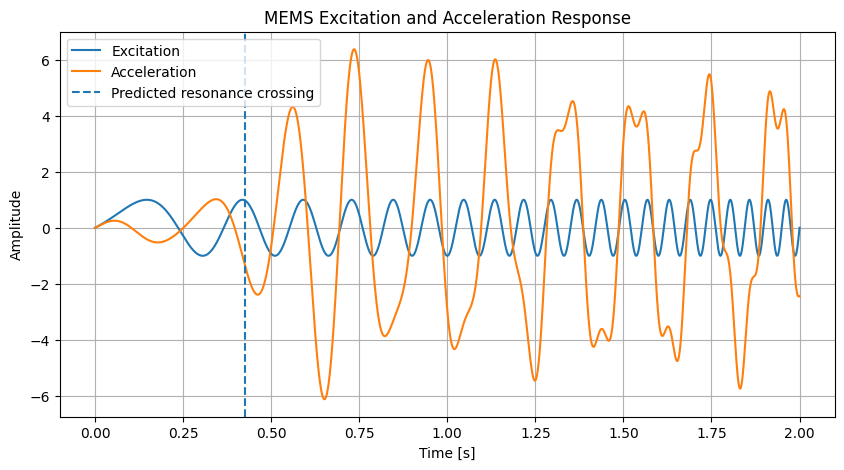

In [12]:
# PLOT THE EXCITATION AND ACCELERATION RESPONSE


# Create a new figure.
plt.figure(figsize=(10, 5))


# Plot the input excitation force.
plt.plot(
    simulation_result.time,
    simulation_result.excitation,
    label="Excitation"
)


# Plot the simulated acceleration response.
plt.plot(
    simulation_result.time,
    simulation_result.acceleration,
    label="Acceleration"
)


# Mark the predicted time at which the chirp reaches
# the natural frequency of the system.
plt.axvline(
    resonance_crossing_time,
    linestyle="--",
    label="Predicted resonance crossing"
)


# Add labels and title.
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("MEMS Excitation and Acceleration Response")


# Add legend and grid for readability.
plt.legend()
plt.grid(True)


# Display the figure.
plt.show()

## Deterministic Time-Domain Response

The deterministic simulation shows the response of the baseline dynamical system to the linear chirp excitation.

The excitation frequency increases continuously throughout the experiment, as indicated by the progressively shorter oscillation periods of the input signal.

The predicted natural-frequency crossing occurs at

$$
t_{\mathrm{res}} = 0.424518\ \text{s}.
$$

Before this region, the acceleration response remains relatively small. After the excitation approaches the natural-frequency region, the acceleration response increases substantially.

The largest response does not appear exactly at the predicted frequency-crossing time. Instead, a delayed response is observed. This is consistent with the transient nature of the chirp experiment: the mechanical system requires time to accumulate and redistribute energy, while the very small damping ratio allows oscillations to persist.

The figure therefore provides qualitative evidence that the simulated system responds strongly when the excitation passes through its dynamically important frequency range. However, the exact location of the maximum response should be determined numerically rather than estimated visually from the plot.

The excitation and acceleration are different physical quantities and therefore should not be quantitatively compared using their plotted amplitudes alone. Separate or appropriately labelled axes will be used for final scientific visualizations.

In [13]:
# LOCATE THE MAXIMUM ABSOLUTE ACCELERATION RESPONSE

# The acceleration can be either positive or negative.
#
# Therefore, we use the absolute value to find the largest
# acceleration magnitude regardless of its direction.

peak_acceleration_index = np.argmax(
    np.abs(simulation_result.acceleration)
)


# Use that index to obtain the corresponding acceleration
# and time values.

peak_acceleration = simulation_result.acceleration[
    peak_acceleration_index
]

peak_acceleration_time = simulation_result.time[
    peak_acceleration_index
]


# Because the excitation is a linear chirp, we can also
# calculate the excitation frequency at the exact time
# when the largest acceleration occurs.

frequency_at_peak_acceleration = (
    start_frequency
    + sweep_rate * peak_acceleration_time
)


# Calculate how much later the maximum response occurs
# relative to the natural-frequency crossing.

response_delay = (
    peak_acceleration_time
    - resonance_crossing_time
)


print(f"Peak acceleration:              {peak_acceleration:.6f}")
print(f"Time of peak acceleration:      {peak_acceleration_time:.6f} s")
print(f"Excitation frequency at peak:   {frequency_at_peak_acceleration:.6f} Hz")
print(f"Delay after resonance crossing: {response_delay:.6f} s")

Peak acceleration:              6.375896
Time of peak acceleration:      0.735600 s
Excitation frequency at peak:   7.988200 Hz
Delay after resonance crossing: 0.311082 s


A numerical search for the largest absolute acceleration gives

$$
a_{\mathrm{peak}} = 6.375896,
$$

occurring at

$$
t_{\mathrm{peak}} = 0.735600\ \text{s}.
$$

At this time, the instantaneous chirp frequency is approximately

$$
f(t_{\mathrm{peak}}) = 7.988200\ \text{Hz}.
$$

The maximum acceleration therefore occurs approximately

$$
0.311082\ \text{s}
$$

after the excitation crosses the calculated natural frequency.

This delayed maximum should not be interpreted as a natural frequency of approximately $7.99$ Hz. The natural frequency remains approximately $5.03$ Hz for the current linear model. Instead, the delayed peak reflects the transient response of the lightly damped system under a continuously swept excitation.

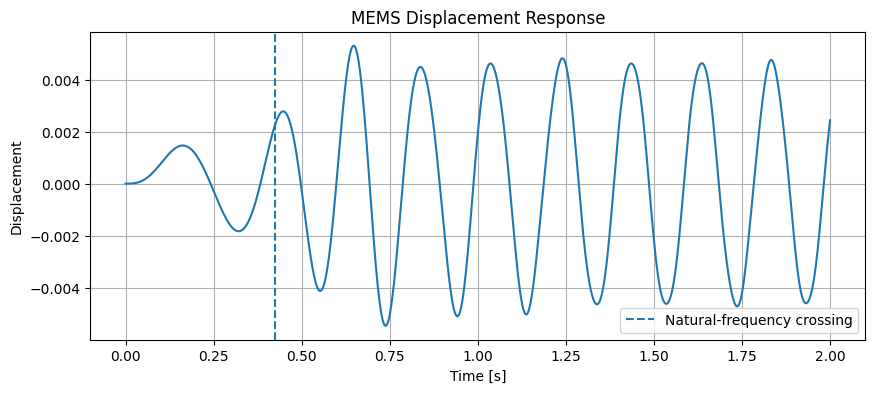

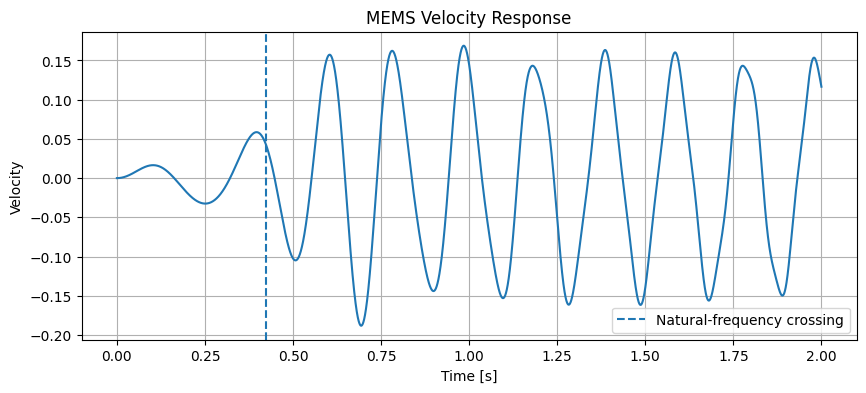

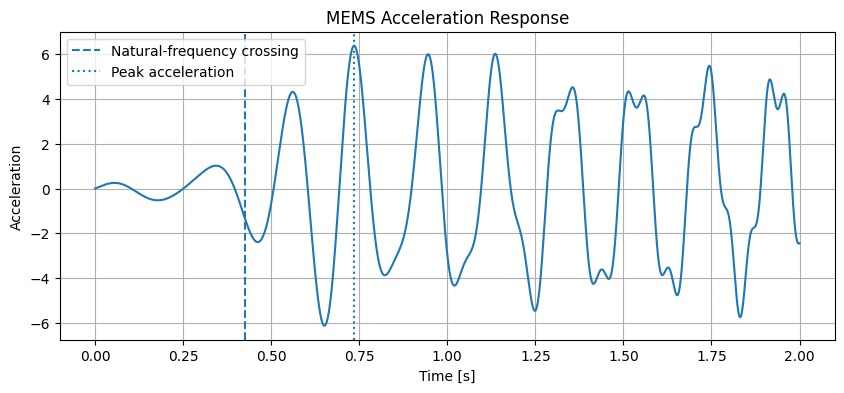

In [14]:
# PLOT THE MAIN TIME-DOMAIN SYSTEM RESPONSES

# Create a figure for the displacement response.
plt.figure(figsize=(10, 4))

plt.plot(
    simulation_result.time,
    simulation_result.displacement
)

plt.axvline(
    resonance_crossing_time,
    linestyle="--",
    label="Natural-frequency crossing"
)

plt.xlabel("Time [s]")
plt.ylabel("Displacement")
plt.title("MEMS Displacement Response")
plt.legend()
plt.grid(True)
plt.show()


# Create a separate figure for the velocity response.
plt.figure(figsize=(10, 4))

plt.plot(
    simulation_result.time,
    simulation_result.velocity
)

plt.axvline(
    resonance_crossing_time,
    linestyle="--",
    label="Natural-frequency crossing"
)

plt.xlabel("Time [s]")
plt.ylabel("Velocity")
plt.title("MEMS Velocity Response")
plt.legend()
plt.grid(True)
plt.show()


# Create a separate figure for the acceleration response.
plt.figure(figsize=(10, 4))

plt.plot(
    simulation_result.time,
    simulation_result.acceleration
)

plt.axvline(
    resonance_crossing_time,
    linestyle="--",
    label="Natural-frequency crossing"
)

plt.axvline(
    peak_acceleration_time,
    linestyle=":",
    label="Peak acceleration"
)

plt.xlabel("Time [s]")
plt.ylabel("Acceleration")
plt.title("MEMS Acceleration Response")
plt.legend()
plt.grid(True)
plt.show()

## Interpretation of the State Responses

The displacement, velocity, and acceleration responses all show that the system begins with a relatively small response and then develops stronger oscillations after the chirp excitation approaches the natural-frequency region.

The displacement response represents the position of the oscillating structure, while the velocity and acceleration responses represent its first and second time derivatives, respectively. Their extrema therefore do not occur at the same times.

The natural-frequency crossing occurs at approximately

$$
t_{\mathrm{res}} = 0.424518\ \text{s},
$$

whereas the maximum absolute acceleration occurs later at

$$
t_{\mathrm{peak}} = 0.735600\ \text{s}.
$$

This confirms that the system exhibits a transient swept-frequency response rather than an instantaneous steady-state resonance response. The very small damping ratio allows energy introduced near the resonance region to persist and influence the response after the excitation frequency has moved beyond the natural frequency.

The simulated displacement, velocity, and acceleration signals therefore show qualitatively consistent behaviour for a lightly damped mass-spring-damper system excited by a chirp signal.

In [15]:
# CREATE A TABULAR DATASET FROM THE SIMULATION RESULT


# The simulation currently stores each signal as a separate
# NumPy array inside simulation_result.
#
# We now combine these arrays into a pandas DataFrame.
#
# This gives us a table in which every row represents one
# time sample of the experiment.

baseline_data = pd.DataFrame(
    {
        "time": simulation_result.time,
        "excitation": simulation_result.excitation,
        "displacement": simulation_result.displacement,
        "velocity": simulation_result.velocity,
        "acceleration": simulation_result.acceleration,
        "measured_signal": simulation_result.measured_signal,
    }
)


# Display the first few rows of the dataset.
baseline_data.head()

,time,excitation,displacement,velocity,acceleration,measured_signal
0,0.0000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000
1,0.0001,0.000629,1.047444e-12,3.142576e-08,0.000629,0.000629
2,0.0002,0.001258,8.381102e-12,1.257422e-07,0.001258,0.001258
3,0.0003,0.001888,2.829303e-11,2.830075e-07,0.001888,0.001888
4,0.0004,0.002518,6.708149e-11,5.032792e-07,0.002518,0.002518


In [16]:
# VERIFY THE BASELINE DATASET

# Display the number of rows and columns in the DataFrame.
#
# We expect:
#
#     20001 rows
#     6 columns

print(f"Dataset shape: {baseline_data.shape}")


# Check whether the measured signal is identical to the
# simulated acceleration.
#
# Since the current sensor has:
#
#     gain = 1
#     bias = 0
#     noise = 0
#
# these two signals should be equal.

sensor_matches_true_signal = np.allclose(
    baseline_data["acceleration"],
    baseline_data["measured_signal"]
)

print(
    f"Measured signal matches true acceleration: "
    f"{sensor_matches_true_signal}"
)


# Check whether the DataFrame contains any missing values.
missing_values = baseline_data.isna().sum()

print()
print("Missing values:")
print(missing_values)

Dataset shape: (20001, 6)
Measured signal matches true acceleration: True

Missing values:
time               0
excitation         0
displacement       0
velocity           0
acceleration       0
measured_signal    0
dtype: int64


In [17]:
# SAVE THE DETERMINISTIC BASELINE DATASET

# Create the path to the raw-data directory.
#
# This uses the project path helper from src/utils.py,
# so the notebook does not need a hard-coded Windows path.

raw_data_directory = data_path("raw")


# Make sure the directory exists.
ensure_directory(raw_data_directory)


# Define the complete file path for the baseline experiment.
baseline_data_path = (
    raw_data_directory
    / "deterministic_baseline.csv"
)


# Save the pandas DataFrame as a CSV file.
#
# index=False prevents pandas from creating an unnecessary
# additional column containing row numbers.

baseline_data.to_csv(
    baseline_data_path,
    index=False
)


# Print the location so that we can confirm where the file
# has been stored.
print(f"Baseline dataset saved to:")
print(baseline_data_path)

Baseline dataset saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\data\raw\deterministic_baseline.csv


In [18]:
# RELOAD AND VERIFY THE SAVED BASELINE DATASET

# Read the CSV file back into pandas.
#
# This checks that the file was saved correctly and that it can
# be loaded again in future notebooks.

reloaded_baseline_data = pd.read_csv(
    baseline_data_path
)


# Display the shape of the reloaded dataset.
print(
    f"Reloaded dataset shape: "
    f"{reloaded_baseline_data.shape}"
)


# Check whether the reloaded data are numerically equal
# to the original DataFrame.
data_matches = np.allclose(
    reloaded_baseline_data.to_numpy(),
    baseline_data.to_numpy()
)

print(
    f"Reloaded data match original data: "
    f"{data_matches}"
)

Reloaded dataset shape: (20001, 6)
Reloaded data match original data: True


In [19]:
# SAVE THE MAIN DYNAMICS FIGURES


# Create the directory in which the deterministic
# dynamics figures will be stored.

dynamics_figure_directory = figures_path("dynamics")

ensure_directory(dynamics_figure_directory)



# 1. EXCITATION AND ACCELERATION RESPONSE

plt.figure(figsize=(10, 5))

plt.plot(
    simulation_result.time,
    simulation_result.excitation,
    label="Excitation"
)

plt.plot(
    simulation_result.time,
    simulation_result.acceleration,
    label="Acceleration"
)

plt.axvline(
    resonance_crossing_time,
    linestyle="--",
    label="Natural-frequency crossing"
)

plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("MEMS Excitation and Acceleration Response")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    dynamics_figure_directory
    / "excitation_acceleration_response.png",
    dpi=300
)

plt.close()



# 2. DISPLACEMENT RESPONSE


plt.figure(figsize=(10, 4))

plt.plot(
    simulation_result.time,
    simulation_result.displacement
)

plt.axvline(
    resonance_crossing_time,
    linestyle="--",
    label="Natural-frequency crossing"
)

plt.xlabel("Time [s]")
plt.ylabel("Displacement")
plt.title("MEMS Displacement Response")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    dynamics_figure_directory
    / "displacement_response.png",
    dpi=300
)

plt.close()



# 3. VELOCITY RESPONSE


plt.figure(figsize=(10, 4))

plt.plot(
    simulation_result.time,
    simulation_result.velocity
)

plt.axvline(
    resonance_crossing_time,
    linestyle="--",
    label="Natural-frequency crossing"
)

plt.xlabel("Time [s]")
plt.ylabel("Velocity")
plt.title("MEMS Velocity Response")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    dynamics_figure_directory
    / "velocity_response.png",
    dpi=300
)

plt.close()



# 4. ACCELERATION RESPONSE

plt.figure(figsize=(10, 4))

plt.plot(
    simulation_result.time,
    simulation_result.acceleration
)

plt.axvline(
    resonance_crossing_time,
    linestyle="--",
    label="Natural-frequency crossing"
)

plt.axvline(
    peak_acceleration_time,
    linestyle=":",
    label="Peak acceleration"
)

plt.xlabel("Time [s]")
plt.ylabel("Acceleration")
plt.title("MEMS Acceleration Response")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    dynamics_figure_directory
    / "acceleration_response.png",
    dpi=300
)

plt.close()


print("Dynamics figures saved to:")
print(dynamics_figure_directory)

Dynamics figures saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\dynamics


## Notebook 01 Summary

This notebook established and validated the deterministic baseline model used throughout the project.

A simplified MEMS dynamical system was represented by the mass-spring-damper equation

$$
m\ddot{x}(t) + c\dot{x}(t) + kx(t) = F(t),
$$

with the nonlinear stiffness term initially disabled.

For the baseline parameter set, the natural frequency was calculated as

$$
f_n = 5.032921\ \text{Hz},
$$

with a damping ratio of

$$
\zeta = 0.00126491.
$$

The system was excited using a linear chirp from $1$ Hz to $20$ Hz over $2$ s. The excitation crossed the calculated natural frequency at approximately

$$
t_{\mathrm{res}} = 0.424518\ \text{s}.
$$

The numerical simulation produced displacement, velocity, acceleration, excitation, and sensor-measurement time series containing $20\,001$ samples.

The largest absolute acceleration was

$$
a_{\mathrm{peak}} = 6.375896,
$$

occurring at

$$
t_{\mathrm{peak}} = 0.735600\ \text{s}.
$$

The delayed peak relative to the natural-frequency crossing demonstrated the transient response of the lightly damped system under swept-frequency excitation.

An ideal sensor model was used for the baseline experiment, with unit gain, zero bias, and zero measurement noise. Therefore, the measured signal was identical to the true acceleration signal.

The resulting deterministic dataset was validated, contained no missing values, and was saved as

`data/raw/deterministic_baseline.csv`.

The main time-domain figures were also saved in

`figures/dynamics/`.

This deterministic experiment provides the reference case required before introducing uncertain parameters, environmental variation, sensor imperfections, and repeated simulations through Monte Carlo analysis.